In [3]:
import pandas as pd

df = pd.read_csv("/content/city_day.csv")
print(df.shape)
df.head()

(29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [4]:
df["Date"] = pd.to_datetime(df["Date"])

print("Cities:", df["City"].nunique())
print("From", df["Date"].min().date(), "to", df["Date"].max().date())
print()
print("Empty cells in each column:")
print(df.isna().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Cities: 26
From 2015-01-01 to 2020-07-01

Empty cells in each column:
City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

Duplicate rows: 0


In [5]:
# Xylene is empty in 61% of rows, so drop it
df = df.drop(columns=["Xylene"])

# For AQI questions, keep only rows that have an AQI value
aqi = df.dropna(subset=["AQI"]).copy()
aqi["Year"] = aqi["Date"].dt.year
aqi["Month"] = aqi["Date"].dt.month

print(aqi.shape)
print()
print("Days of AQI data per city:")
print(aqi["City"].value_counts())

(24850, 17)

Days of AQI data per city:
City
Delhi                 1999
Bengaluru             1910
Lucknow               1893
Chennai               1884
Hyderabad             1880
Patna                 1459
Gurugram              1453
Ahmedabad             1334
Visakhapatnam         1171
Amritsar              1126
Jaipur                1094
Thiruvananthapuram    1052
Amaravati              841
Mumbai                 775
Jorapokhar             771
Kolkata                754
Brajrajnagar           713
Talcher                698
Guwahati               495
Coimbatore             344
Chandigarh             299
Bhopal                 278
Shillong               205
Kochi                  158
Ernakulam              153
Aizawl                 111
Name: count, dtype: int64


City
Ahmedabad             452.0
Delhi                 259.0
Patna                 241.0
Gurugram              225.0
Lucknow               218.0
Jaipur                134.0
Amritsar              120.0
Visakhapatnam         117.0
Chennai               115.0
Hyderabad             109.0
Bengaluru              94.0
Thiruvananthapuram     76.0
Name: AQI, dtype: float64


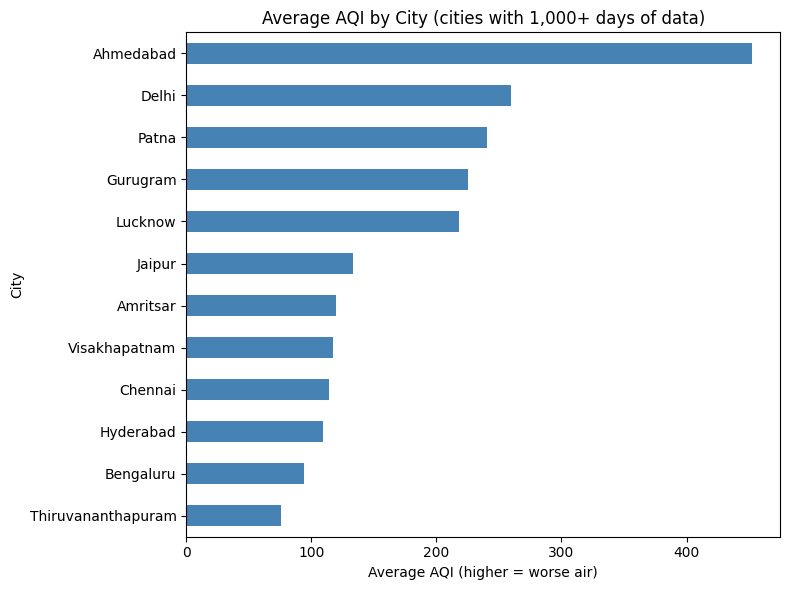

In [6]:
import matplotlib.pyplot as plt

# keep only cities with at least 1,000 days of AQI data
counts = aqi["City"].value_counts()
big_cities = counts[counts >= 1000].index
aqi_big = aqi[aqi["City"].isin(big_cities)]

# average AQI per city, worst first
city_avg = aqi_big.groupby("City")["AQI"].mean().sort_values(ascending=False)
print(city_avg.round(0))

# chart
city_avg.plot(kind="barh", figsize=(8, 6), color="steelblue")
plt.gca().invert_yaxis()
plt.title("Average AQI by City (cities with 1,000+ days of data)")
plt.xlabel("Average AQI (higher = worse air)")
plt.tight_layout()
plt.savefig("q1_city_aqi.png", dpi=150)
plt.show()

In [8]:
ahd = aqi[aqi["City"] == "Ahmedabad"]
print("Ahmedabad: average", round(ahd["AQI"].mean()), "| median", round(ahd["AQI"].median()), "| highest", ahd["AQI"].max())
print()
print("Ahmedabad by year (days of data, average AQI):")
print(ahd.groupby("Year")["AQI"].agg(["count", "mean"]).round(0))
print()
print("Delhi by year:")
dl = aqi[aqi["City"] == "Delhi"]
print(dl.groupby("Year")["AQI"].agg(["count", "mean"]).round(0))

Ahmedabad: average 452 | median 384 | highest 2049.0

Ahmedabad by year (days of data, average AQI):
      count   mean
Year              
2015    263  311.0
2016    117  310.0
2017     69  559.0
2018    357  622.0
2019    352  516.0
2020    176  242.0

Delhi by year:
      count   mean
Year              
2015    365  297.0
2016    365  301.0
2017    356  257.0
2018    365  249.0
2019    365  232.0
2020    183  182.0


In [9]:
# AQI above 500 is beyond the official scale, so where do those readings come from?
over = aqi_big[aqi_big["AQI"] > 500]
print("Readings above 500, by city:")
print(over["City"].value_counts())
print()

# the median is not pulled up by extreme values, so it is a fairer ranking
city_med = aqi_big.groupby("City")["AQI"].median().sort_values(ascending=False)
print("Median AQI by city:")
print(city_med.round(0))

Readings above 500, by city:
City
Ahmedabad    412
Delhi         48
Patna         25
Gurugram      22
Lucknow       15
Amritsar       4
Hyderabad      4
Name: count, dtype: int64

Median AQI by city:
City
Ahmedabad             384.0
Delhi                 257.0
Patna                 215.0
Gurugram              208.0
Lucknow               198.0
Jaipur                122.0
Visakhapatnam         106.0
Hyderabad             104.0
Amritsar              101.0
Chennai               100.0
Bengaluru              86.0
Thiruvananthapuram     68.0
Name: AQI, dtype: float64


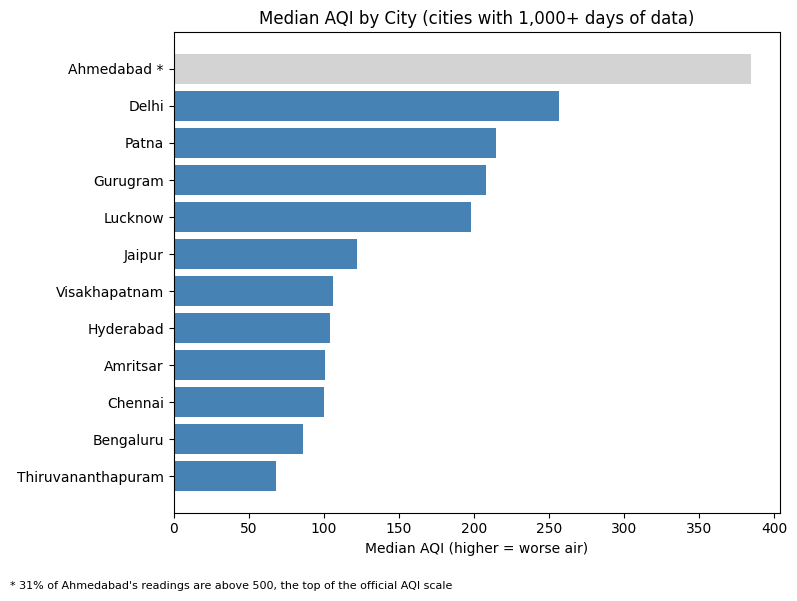

In [10]:
# Question 1 : median AQI is less affected by extreme readings
city_med = aqi_big.groupby("City")["AQI"].median().sort_values(ascending=False)

colors = ["lightgrey" if c == "Ahmedabad" else "steelblue" for c in city_med.index]
labels = [c + " *" if c == "Ahmedabad" else c for c in city_med.index]

plt.figure(figsize=(8, 6))
plt.barh(labels, city_med.values, color=colors)
plt.gca().invert_yaxis()
plt.title("Median AQI by City (cities with 1,000+ days of data)")
plt.xlabel("Median AQI (higher = worse air)")
plt.figtext(0.01, 0.01, "* 31% of Ahmedabad's readings are above 500, the top of the official AQI scale", fontsize=8)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("q1_city_aqi.png", dpi=150)
plt.show()

Cities with steady data: ['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Lucknow']

City  Bengaluru  Chennai  Delhi  Hyderabad  Lucknow
Year                                               
2016      102.0    129.0  293.0      111.0    238.0
2017       78.0     89.0  280.0      110.0    248.0
2018       81.0     92.0  243.0      100.0    236.0
2019       89.0     92.0  209.0       94.0    193.0


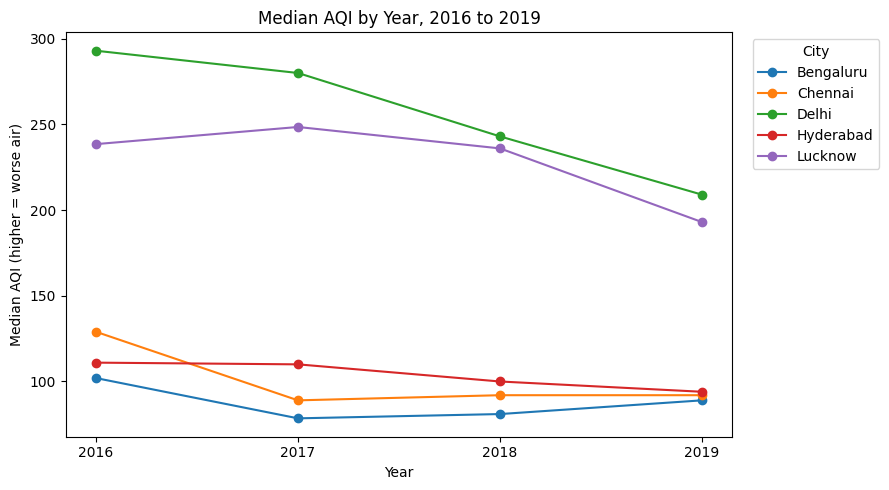

In [11]:
# only full years (2016-2019), and only cities with 300+ days of data in each of those years
full = aqi[aqi["Year"].between(2016, 2019)]
days = full.groupby(["City", "Year"])["AQI"].count().unstack()
steady = days[(days >= 300).all(axis=1)].index
print("Cities with steady data:", list(steady))
print()

# median AQI per city per year
trend = full[full["City"].isin(steady)].groupby(["Year", "City"])["AQI"].median().unstack()
print(trend.round(0))

trend.plot(figsize=(9, 5), marker="o")
plt.title("Median AQI by Year, 2016 to 2019")
plt.ylabel("Median AQI (higher = worse air)")
plt.xticks([2016, 2017, 2018, 2019])
plt.legend(title="City", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("q2_yearly_trend.png", dpi=150)
plt.show()

City   Bengaluru  Chennai  Delhi  Hyderabad  Lucknow
Month                                               
1          106.0    133.0  378.0      146.0    359.0
2           99.0    118.0  312.0      118.0    315.0
3          108.0    110.0  225.0      117.0    226.0
4          107.0     89.0  259.0      103.0    222.0
5           80.0     94.0  254.0      105.0    219.0
6           64.0     92.0  187.0       74.0    160.0
7           64.0     84.0  114.0       58.0     86.0
8           62.0     90.0  104.0       60.0     84.0
9           70.0     98.0  118.0       65.0     89.0
10          88.0     89.0  312.0      102.0    255.0
11          88.0     94.0  377.0      127.0    358.0
12          93.0     93.0  382.0      132.0    354.0


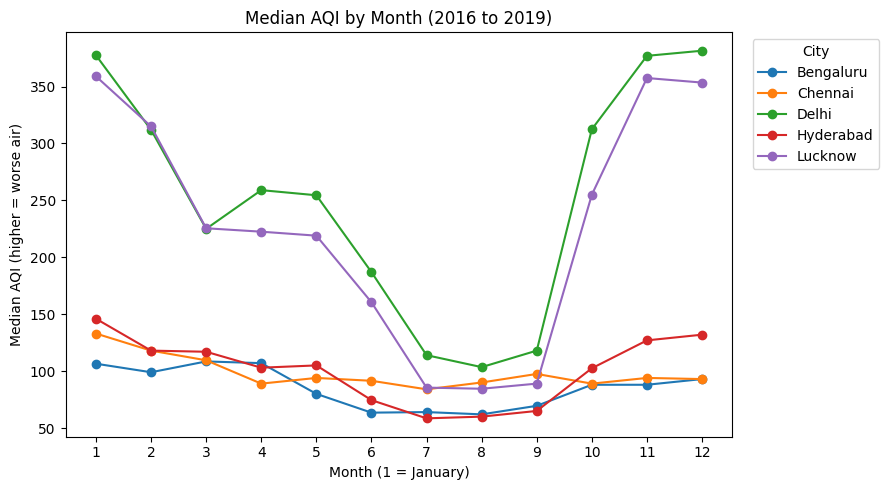

In [12]:
# median AQI for each month (pooled over 2016-2019), for the 5 cities with steady data
months = full[full["City"].isin(steady)].groupby(["Month", "City"])["AQI"].median().unstack()
print(months.round(0))

months.plot(figsize=(9, 5), marker="o")
plt.title("Median AQI by Month (2016 to 2019)")
plt.ylabel("Median AQI (higher = worse air)")
plt.xlabel("Month (1 = January)")
plt.xticks(range(1, 13))
plt.legend(title="City", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("q3_monthly_pattern.png", dpi=150)
plt.show()

                    count_2019  median_2019  count_2020  median_2020  change_%
City                                                                          
Ahmedabad                   90        412.0          96        122.0     -71.0
Lucknow                     98        189.0          98         92.0     -51.0
Delhi                       98        208.0          98        123.0     -41.0
Bengaluru                   98        106.0          98         66.0     -38.0
Gurugram                    97        201.0          98        128.0     -37.0
Amaravati                   94         79.0          98         50.0     -37.0
Kolkata                     98         82.0          98         52.0     -37.0
Amritsar                    98        105.0          92         68.0     -35.0
Hyderabad                   98         98.0          98         64.0     -35.0
Visakhapatnam               96        104.0          96         68.0     -35.0
Guwahati                    96         76.0         

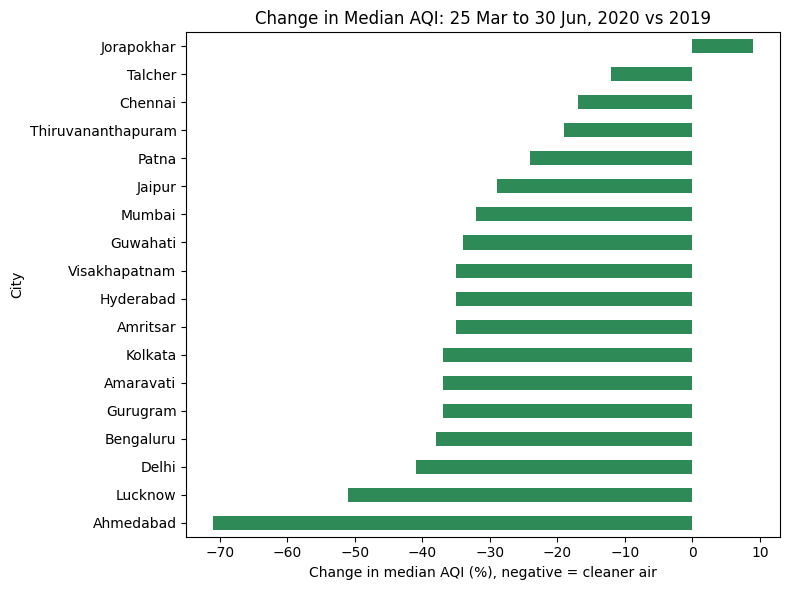

In [13]:
# same dates (25 March to 30 June) in 2019 and 2020
def period(year):
    start = pd.Timestamp(f"{year}-03-25")
    end = pd.Timestamp(f"{year}-06-30")
    return aqi[(aqi["Date"] >= start) & (aqi["Date"] <= end)]

p19 = period(2019).groupby("City")["AQI"].agg(["count", "median"])
p20 = period(2020).groupby("City")["AQI"].agg(["count", "median"])

cmp = p19.join(p20, lsuffix="_2019", rsuffix="_2020").dropna()
cmp = cmp[(cmp["count_2019"] >= 60) & (cmp["count_2020"] >= 60)]   # need 60+ days in both years
cmp["change_%"] = ((cmp["median_2020"] / cmp["median_2019"] - 1) * 100).round(0)
cmp = cmp.sort_values("change_%")
print(cmp.round(0))

cmp["change_%"].plot(kind="barh", figsize=(8, 6), color="seagreen")
plt.title("Change in Median AQI: 25 Mar to 30 Jun, 2020 vs 2019")
plt.xlabel("Change in median AQI (%), negative = cleaner air")
plt.tight_layout()
plt.savefig("q4_lockdown_change.png", dpi=150)
plt.show()